# 03. Baselines

**Owner:** Member A (Logistic Regression)
**Step 9:** establish what simple rules achieve, so every model score that follows has a reference point.

A score such as PR-AUC 0.69 means little on its own. It might be excellent or barely better than guessing, depending on how rare outbreaks are and how predictable they are without any model. A baseline is a rule that involves no learning. If a trained model cannot beat it, the model adds nothing.

**The four baselines, from weakest to strongest**

| Baseline | The rule | What it shows |
|---|---|---|
| Always no outbreak | Predict "no outbreak" for every week | The accuracy trap: high accuracy while catching nothing |
| Random guessing | Guess "outbreak" at the training outbreak rate | The floor for PR-AUC, which equals the outbreak rate |
| Persistence | Outbreak in two weeks if the district is in outbreak now | How far the current state alone gets you |
| Persistence score | Rank weeks by this week's cases divided by the district's outbreak threshold | The same information as persistence, but as a ranking, so its PR-AUC is directly comparable with a model's |

**Scoring.** Every baseline is scored with `classification_metrics` from `src/evaluation.py`, the same function both models will use, on:

- the five expanding-window cross-validation years (2016 to 2020) that both models are tuned on, and
- the validation years 2021 to 2022.

The test years 2023 to 2025 stay sealed until step 11, where baselines and models are scored on them together.

In [1]:
import sys
from pathlib import Path

# Make the project root importable so the shared `src` modules work from notebooks/.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from sklearn.dummy import DummyClassifier

from src import config, viz
from src.evaluation import classification_metrics, cross_validate
from src.preprocessing import (
    CV_VALIDATION_YEARS, MODEL_FEATURES, build_model_frame, expanding_year_folds,
    make_selected_preprocessor,
)

viz.set_style()
pd.set_option("display.width", 140)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

In [2]:
frame = build_model_frame()
train_frame = frame[frame["split"] == "train"].reset_index(drop=True)
val_frame = frame[frame["split"] == "val"].reset_index(drop=True)
folds = expanding_year_folds(train_frame)

periods = {str(year): train_frame.iloc[val_idx] for year, (_, val_idx) in zip(CV_VALIDATION_YEARS, folds)}
periods["2021-2022"] = val_frame
outbreak_rates = pd.DataFrame({
    "weeks scored": {p: len(rows) for p, rows in periods.items()},
    "outbreak weeks": {p: int(rows["target"].sum()) for p, rows in periods.items()},
    "outbreak rate": {p: rows["target"].mean() for p, rows in periods.items()},
})
outbreak_rates.index.name = "evaluated on"
outbreak_rates

,weeks scored,outbreak weeks,outbreak rate
evaluated on,,,
2016,1325,59,0.045
2017,1300,666,0.512
2018,1300,103,0.079
2019,1300,357,0.275
2020,1250,74,0.059
2021-2022,2575,77,0.030


The outbreak rate swings from 3% to 51% between years. This matters for reading every result below: the PR-AUC of random guessing equals the outbreak rate, so a PR-AUC of 0.5 is poor in 2017 (51% outbreaks) and strong in 2020 (6%). Scores should only be compared within the same year or period, never across them.

## 1. The baselines

The two guessing rules are scikit-learn `DummyClassifier` models. They learn one thing from their training rows, the outbreak rate, and ignore every feature. They are refitted on each fold's training rows, exactly as a model would be.

The two persistence rules need no fitting. Each returns a score per week and a decision threshold:

- **Persistence** scores 1 if the district is in outbreak now and 0 otherwise. With the threshold at 0.5 it predicts an outbreak in two weeks whenever there is one now.
- **Persistence score** uses `cases_rel_threshold`, this week's cases divided by the district's outbreak threshold. With the threshold at 1.0 it makes exactly the same yes or no predictions as persistence. The difference is the ranking: a week at 0.95 of the threshold ranks above a week at 0.10, while persistence scores both as 0. PR-AUC measures ranking quality, so this baseline is the fair comparison for a model that outputs probabilities.

In [3]:
def dummy_rule(strategy):
    """A DummyClassifier that learns only the training outbreak rate; the input column is ignored."""
    def scores(train_rows, eval_rows):
        model = DummyClassifier(strategy=strategy, random_state=config.RANDOM_SEED)
        model.fit(train_rows[["cases_now"]], train_rows["target"])
        return model.predict_proba(eval_rows[["cases_now"]])[:, 1]
    return scores


# name: (scoring rule, decision threshold)
BASELINES = {
    "Always no outbreak": (dummy_rule("most_frequent"), 0.5),
    "Random guessing": (dummy_rule("stratified"), 0.5),
    "Persistence": (lambda train_rows, eval_rows: eval_rows["outbreak_now"].to_numpy(), 0.5),
    "Persistence score": (lambda train_rows, eval_rows: eval_rows["cases_rel_threshold"].to_numpy(), 1.0),
}


def score_baselines(train_rows, eval_rows, period):
    """Every metric for every baseline, fitted on train_rows and scored on eval_rows."""
    rows = []
    for name, (rule, threshold) in BASELINES.items():
        metrics = classification_metrics(eval_rows["target"], rule(train_rows, eval_rows), threshold)
        rows.append({"baseline": name, "evaluated on": period, **metrics})
    return rows


rows = []
for year, (train_idx, val_idx) in zip(CV_VALIDATION_YEARS, folds):
    rows += score_baselines(train_frame.iloc[train_idx], train_frame.iloc[val_idx], str(year))
rows += score_baselines(train_frame, val_frame, "2021-2022")
results = pd.DataFrame(rows)

SUMMARY_METRICS = ["PR-AUC", "ROC-AUC", "precision", "recall", "F1", "MCC", "accuracy"]
cv_results = results[results["evaluated on"] != "2021-2022"]
val_results = results[results["evaluated on"] == "2021-2022"].set_index("baseline")
print(f"Scored {len(BASELINES)} baselines on {cv_results['evaluated on'].nunique()} cross-validation years and on 2021-2022.")

Scored 4 baselines on 5 cross-validation years and on 2021-2022.


## 2. Cross-validation years, 2016 to 2020

Mean of each metric across the five validation years. Precision, recall, F1, MCC and accuracy use each baseline's decision threshold; PR-AUC and ROC-AUC use the scores directly.

In [4]:
cv_summary = cv_results.groupby("baseline", sort=False)[SUMMARY_METRICS].mean()
cv_summary

,PR-AUC,ROC-AUC,precision,recall,F1,MCC,accuracy
baseline,,,,,,,
Always no outbreak,0.194,0.500,0.000,0.000,0.000,0.000,0.806
Random guessing,0.194,0.495,0.191,0.043,0.055,-0.008,0.768
Persistence,0.496,0.796,0.624,0.664,0.638,0.568,0.906
Persistence score,0.687,0.892,0.624,0.664,0.638,0.568,0.906


In [5]:
pr_auc_by_year = cv_results.pivot_table(index="baseline", columns="evaluated on", values="PR-AUC", sort=False)
pr_auc_by_year.loc["Outbreak rate"] = outbreak_rates.loc[pr_auc_by_year.columns, "outbreak rate"]
pr_auc_by_year["mean"] = pr_auc_by_year.mean(axis=1)
pr_auc_by_year

evaluated on,2016,2017,2018,2019,2020,mean
baseline,,,,,,
Always no outbreak,0.045,0.512,0.079,0.275,0.059,0.194
Random guessing,0.046,0.513,0.078,0.273,0.058,0.194
Persistence,0.121,0.741,0.336,0.749,0.535,0.496
Persistence score,0.291,0.890,0.544,0.916,0.796,0.687
Outbreak rate,0.045,0.512,0.079,0.275,0.059,0.194


**Findings**

- **Both guessing rules sit on the floor.** Their PR-AUC is within 0.002 of the outbreak rate in every year (0.194 on average) and their ROC-AUC is about 0.5. Always no outbreak still reaches 0.806 mean accuracy without catching a single outbreak. In 2016 it is even more accurate than persistence (0.955 against 0.943). Because there were so few outbreaks to miss.
- **Persistence is a real predictor.** Predicting an outbreak in two weeks whenever there is one now gives precision 0.624, recall 0.664 and MCC 0.568.  Outbreaks are persistent, as the autocorrelation in `01a` showed.
- **Ranking matters.** The persistence score makes the same yes or no predictions as persistence, yet its PR-AUC is 0.687 against 0.496. Ordering weeks by how close they are to the threshold puts the weeks about to tip into outbreak near the top of the list, which a 0 or 1 score cannot do.

## 3. How the strongest baseline compares with the step 8 models

The two models below are the step 8 reference models (fixed default settings, not yet tuned) trained on the agreed feature set from `make_selected_preprocessor`. They are scored on the same five folds. The last two rows give each model's PR-AUC minus the persistence score's, so a positive value means the model is ahead in that year.

In [6]:
X, y = train_frame[MODEL_FEATURES], train_frame["target"]
models = cross_validate(make_selected_preprocessor, X, y, folds, label="agreed features (step 8)")
model_pr_auc = models.pivot_table(index="model", columns="fold", values="pr_auc", sort=False)
model_pr_auc.columns = [str(year) for year in CV_VALIDATION_YEARS]
comparison = pd.concat([pr_auc_by_year.loc[["Persistence score"], model_pr_auc.columns], model_pr_auc])
comparison["mean"] = comparison.mean(axis=1)
gap = (comparison.iloc[1:] - comparison.loc["Persistence score"]).rename(index=lambda m: f"{m}: gap")
pd.concat([comparison, gap])

,2016,2017,2018,2019,2020,mean
Persistence score,0.291,0.890,0.544,0.916,0.796,0.687
Logistic Regression,0.274,0.881,0.574,0.913,0.821,0.692
Random Forest,0.238,0.775,0.593,0.895,0.833,0.667
Logistic Regression: gap,-0.018,-0.009,0.030,-0.002,0.025,0.005
Random Forest: gap,-0.053,-0.114,0.049,-0.020,0.037,-0.020


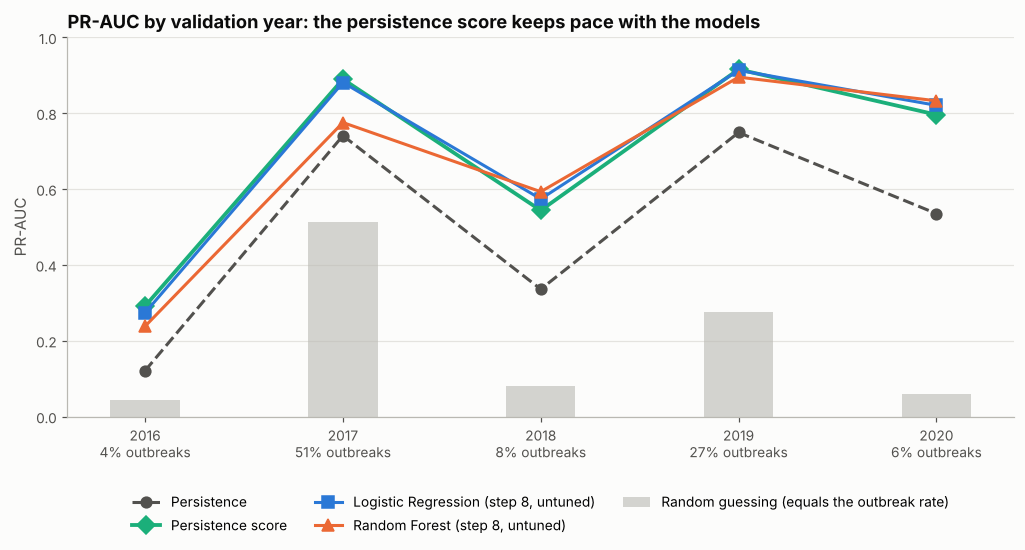

In [7]:
years = [str(year) for year in CV_VALIDATION_YEARS]
x = np.arange(len(years))
rates = outbreak_rates.loc[years, "outbreak rate"].to_numpy()

fig, ax = plt.subplots(figsize=(9.5, 5.2))
ax.bar(x, rates, width=0.35, color=viz.NEUTRAL, alpha=0.6, zorder=1, label="Random guessing (equals the outbreak rate)")
ax.plot(x, pr_auc_by_year.loc["Persistence", years], color=viz.TEXT_MUTED, linestyle="--", linewidth=2,
        marker="o", markersize=7, label="Persistence")
ax.plot(x, pr_auc_by_year.loc["Persistence score", years], color=viz.AQUA, linewidth=2.5,
        marker="D", markersize=8, label="Persistence score", zorder=3)
for (name, row), colour, marker in zip(model_pr_auc.iterrows(), [viz.BLUE, viz.ORANGE], ["s", "^"]):
    ax.plot(x, row[years], color=colour, linewidth=2, marker=marker, markersize=8,
            label=f"{name} (step 8, untuned)", zorder=4)

ax.set_xticks(x, [f"{year}\n{rate:.0%} outbreaks" for year, rate in zip(years, rates)])
ax.set_ylim(0, 1)
ax.set_ylabel("PR-AUC")
ax.set_title("PR-AUC by validation year: the persistence score keeps pace with the models")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=3, frameon=False)
fig.tight_layout()
viz.save(fig, "base_01_pr_auc_by_year")
plt.show()

**Finding.** The persistence score matches the untuned models: mean PR-AUC 0.687, against 0.692 for Logistic Regression and 0.667 for Random Forest. Year by year the picture is mixed. Both models are ahead in 2018 and 2020. The persistence score is ahead in 2016, 2017 and 2019, although Logistic Regression is within 0.01 of it in 2017 and 2019. Random Forest falls furthest behind in the 2017 epidemic year, by 0.114.

Two weeks ahead, most of the predictive signal is simply how high cases are now. This agrees with step 8, where case history was essential and climate added about 0.01 of PR-AUC.

## 4. Validation years, 2021 to 2022

Each baseline is fitted on all training years (2007 to 2020) and scored once on 2021 to 2022. These two years were quiet, with 77 outbreak weeks among 2,575, so every PR-AUC is lower than in cross-validation.

In [8]:
val_results[SUMMARY_METRICS + ["TP", "FP", "FN", "TN"]]

,PR-AUC,ROC-AUC,precision,recall,F1,MCC,accuracy,TP,FP,FN,TN
baseline,,,,,,,,,,,
Always no outbreak,0.030,0.500,0.000,0.000,0.000,0.000,0.970,0,0,77,2498
Random guessing,0.030,0.505,0.034,0.091,0.049,0.007,0.895,7,200,70,2298
Persistence,0.325,0.772,0.558,0.558,0.558,0.545,0.974,43,34,34,2464
Persistence score,0.554,0.933,0.558,0.558,0.558,0.545,0.974,43,34,34,2464


**Findings**

- **The floor drops to 0.030**, the outbreak rate of these two years.
- **Persistence catches 43 of the 77 outbreaks** with 34 false alarms, so precision, recall and F1 are all 0.558, and MCC is 0.545.
- **The persistence score reaches PR-AUC 0.554** against 0.325 for persistence, the same ranking advantage seen in cross-validation.

## 5. The accuracy trap

Outbreaks are a small minority of weeks, so a rule that ignores them entirely still looks accurate. This is why the project uses PR-AUC as the primary metric and reports recall and MCC alongside it.

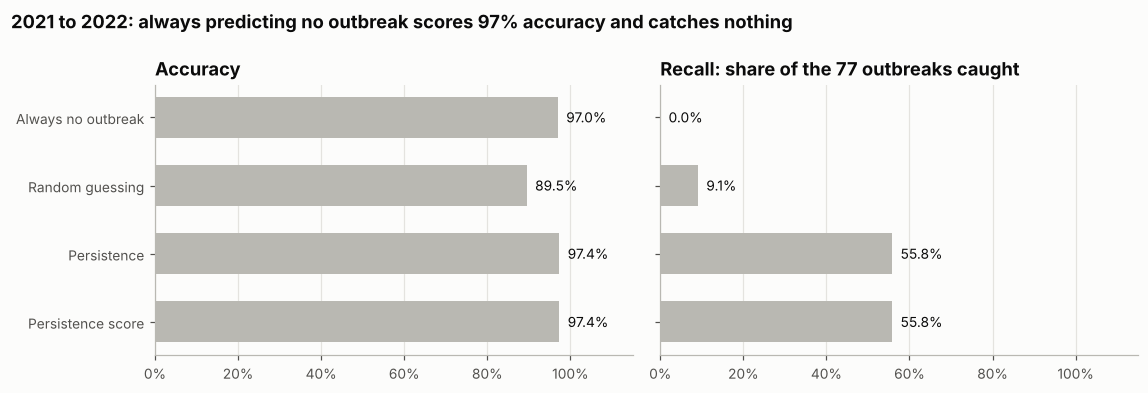

In [9]:
order = list(BASELINES)[::-1]
outbreaks = int(val_results["TP"].iloc[0] + val_results["FN"].iloc[0])
panels = [("accuracy", "Accuracy"), ("recall", f"Recall: share of the {outbreaks} outbreaks caught")]

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.6), sharey=True)
for ax, (metric, title) in zip(axes, panels):
    values = val_results.loc[order, metric]
    ax.barh(order, values, color=viz.NEUTRAL, height=0.6)
    for i, value in enumerate(values):
        ax.text(value + 0.02, i, f"{value:.1%}", va="center", fontsize=9, color=viz.TEXT)
    ax.set_xlim(0, 1.15)
    ax.xaxis.set_major_formatter(PercentFormatter(1.0))
    ax.set_title(title)
    ax.grid(axis="y", visible=False)
fig.suptitle("2021 to 2022: always predicting no outbreak scores 97% accuracy and catches nothing",
             x=0.01, ha="left", fontweight="bold", color=viz.TEXT)
fig.tight_layout()
viz.save(fig, "base_02_accuracy_trap")
plt.show()

**Finding.** Always no outbreak scores 97.0% accuracy on 2021 to 2022, almost the same as persistence at 97.4%, yet it catches none of the 77 outbreaks. Accuracy cannot tell a useless rule from a useful one on this data, so it is reported but never used to choose between models.

## 6. Summary for the report

- **Floor.** Random guessing scores a PR-AUC equal to the outbreak rate: 0.194 on average across 2016 to 2020 and 0.030 on 2021 to 2022.
- **Accuracy is misleading.** Always no outbreak reaches 97.0% accuracy on 2021 to 2022 with zero recall.
- **The strongest baseline is the persistence score**, with PR-AUC 0.687 in cross-validation and 0.554 on 2021 to 2022, well above plain persistence (0.496 and 0.325).
- **The untuned models only match it** in cross-validation (0.692 and 0.667), so the signal two weeks ahead comes mainly from the current case level.

**What step 10 must beat.** A tuned model adds value only if it beats the persistence score: PR-AUC above **0.687** across the 2016 to 2020 folds and above **0.554** on 2021 to 2022. If a tuned model only matches it, that is still a valid result for the critical analysis. One place where models can add value is outbreak onsets, the weeks with no outbreak now but one two weeks later. Plain persistence misses every one of them by definition, and the persistence score can only rank them by how close cases already are to the threshold. Onsets are where trends and climate could add something, and where an early warning matters most.

In [10]:
config.METRICS_DIR.mkdir(parents=True, exist_ok=True)

by_fold = cv_results.copy()
by_fold["outbreak rate"] = by_fold["evaluated on"].map(outbreak_rates["outbreak rate"])
by_fold.to_csv(config.METRICS_DIR / "baseline_by_fold.csv", index=False)

summary = pd.concat({
    "CV mean 2016-2020": cv_summary,
    "2021-2022": val_results[SUMMARY_METRICS],
}, names=["evaluated on", "baseline"]).swaplevel().sort_index(level=0, sort_remaining=False)
summary = summary.reindex(pd.MultiIndex.from_product([list(BASELINES), ["CV mean 2016-2020", "2021-2022"]],
                                                     names=["baseline", "evaluated on"]))
summary.to_csv(config.METRICS_DIR / "baseline_summary.csv")
print("Saved baseline_by_fold.csv and baseline_summary.csv to results/metrics/")
summary

Saved baseline_by_fold.csv and baseline_summary.csv to results/metrics/


PR-AUC  ROC-AUC  precision  recall    F1    MCC  accuracy
baseline           evaluated on                                                                
Always no outbreak CV mean 2016-2020   0.194    0.500      0.000   0.000 0.000  0.000     0.806
                   2021-2022           0.030    0.500      0.000   0.000 0.000  0.000     0.970
Random guessing    CV mean 2016-2020   0.194    0.495      0.191   0.043 0.055 -0.008     0.768
                   2021-2022           0.030    0.505      0.034   0.091 0.049  0.007     0.895
Persistence        CV mean 2016-2020   0.496    0.796      0.624   0.664 0.638  0.568     0.906
                   2021-2022           0.325    0.772      0.558   0.558 0.558  0.545     0.974
Persistence score  CV mean 2016-2020   0.687    0.892      0.624   0.664 0.638  0.568     0.906
                   2021-2022           0.554    0.933      0.558   0.558 0.558  0.545     0.974